# ViT：把图像当成一串小方块

目标：把 28×28 图像切成 16 个 7×7 小块，再用 Transformer 混合这些位置的信息。数据和训练循环继续沿用 LeNet。

从项目根目录运行。`device` 可换为 `"cpu"` 或 `"cuda"`；不固定随机种子。

In [1]:
from qutai import Stream, nn, visualization
from examples.data.data import load_mnist

device = "apple"

## 1. 看数据

仍然使用 MNIST 的同一个小训练子集。图像输入保持 NCHW 形状，切块发生在模型内部。

一批图像的形状： (32, 1, 28, 28)



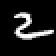
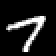
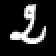
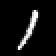

In [3]:
train_inputs, train_targets = load_mnist("train")
test_inputs, test_targets = load_mnist("test")
data = Stream(train_inputs, train_targets, batch_size=32, limit=256, device=device)
inputs, targets = next(iter(data))
print("一批图像的形状：", inputs.shape)
visualization.ImageCombine([visualization.Image.from_tensor(image, value_range=(0, 1), scale=2) for image in inputs[:4]], labels=targets[:4], title="真实 MNIST 与正确标签")

## 2. 搭模型

PatchEmbedding 将每个小块变成 8 个特征，PositionEmbedding 告诉模型它位于哪里。Transformer 关联 16 个位置，最后对位置求平均得到整张图的表示。

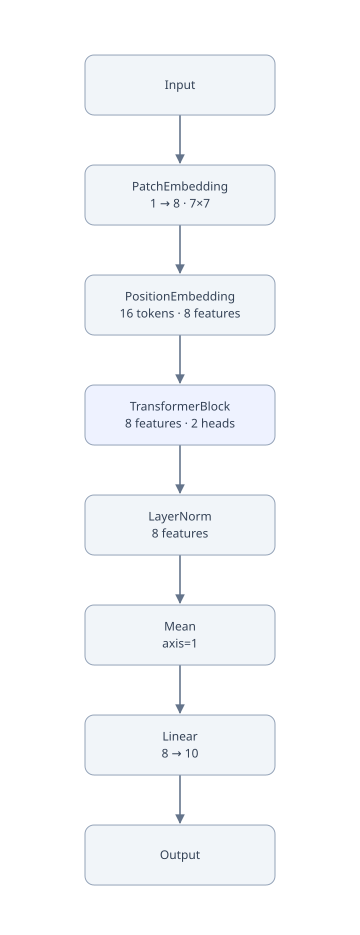

In [5]:
model = nn.Model([
    nn.PatchEmbedding(1, 8, patch_size=7),
    nn.PositionEmbedding(16, 8),
    nn.TransformerBlock(8, heads=2, hidden_features=16),
    nn.LayerNorm(8), nn.Mean(axis=1), nn.Linear(8, 10),
], device=device)
optimizer = nn.AdamW(model, learning_rate=0.003)
loss_function = nn.CrossEntropy()

visualization.Network(model)

## 3. 训练

卷积网络换成了 Transformer，训练循环仍保持不变。这个小模型与小数据量用于学习结构，并不代表完整 ViT 的识别能力。

In [6]:
epochs = 50
# 每轮遍历一次数据；每批独立完成一次参数更新。
for epoch in range(epochs):
    for inputs, targets in data:
        optimizer.zero_grad()
        loss = loss_function(model(inputs), targets)
        loss.backward()
        optimizer.step()
    print(f"epoch {epoch + 1}/{epochs}  loss {loss.item():.6f}")

epoch 1/50  loss 2.321325
epoch 2/50  loss 2.101341
epoch 3/50  loss 2.015240
epoch 4/50  loss 1.951066
epoch 5/50  loss 1.925326
epoch 6/50  loss 1.854967
epoch 7/50  loss 1.685762
epoch 8/50  loss 1.726098
epoch 9/50  loss 1.637624
epoch 10/50  loss 1.459390
epoch 11/50  loss 1.482047
epoch 12/50  loss 1.453421
epoch 13/50  loss 1.382170
epoch 14/50  loss 1.316967
epoch 15/50  loss 1.267632
epoch 16/50  loss 1.127040
epoch 17/50  loss 1.250278
epoch 18/50  loss 1.146866
epoch 19/50  loss 0.986884
epoch 20/50  loss 1.017123
epoch 21/50  loss 1.148738
epoch 22/50  loss 0.887789
epoch 23/50  loss 0.964809
epoch 24/50  loss 0.949173
epoch 25/50  loss 0.896858
epoch 26/50  loss 0.732318
epoch 27/50  loss 0.840324
epoch 28/50  loss 0.880682
epoch 29/50  loss 0.899707
epoch 30/50  loss 0.800069
epoch 31/50  loss 0.650796
epoch 32/50  loss 0.889354
epoch 33/50  loss 0.549076
epoch 34/50  loss 0.656852
epoch 35/50  loss 0.458789
epoch 36/50  loss 0.448202
epoch 37/50  loss 0.416399
epoch 38/5

## 4. 看结果

先查看预测，再查看第一张图上第一个注意力头如何关联各个小块。热力图的行和列都对应 16 个 patch。

这 64 张测试图的准确率：60.9%



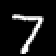
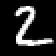
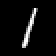
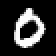

In [8]:
inputs, targets = next(iter(Stream(test_inputs, test_targets, batch_size=64, shuffle=False, device=device)))
predictions = model(inputs, train=False).argmax(axis=-1)
correct = sum(prediction == target for prediction, target in zip(predictions, targets))
print(f"这 64 张测试图的准确率：{correct / len(targets):.1%}")
visualization.ImageCombine([visualization.Image.from_tensor(image, value_range=(0, 1), scale=2) for image in inputs[:4]], labels=[f"正确 {target} / 预测 {prediction}" for target, prediction in zip(targets[:4], predictions[:4])])

In [ ]:
feature_model = nn.Model(model.layers[:2])
tokens = feature_model(inputs[:1], train=False)
block = model.layers[2]
weights = block.attention.weights(block.attention_norm(tokens))[0, 0]
visualization.Heatmap(weights.tolist(), title="16 个图像小块之间的注意力")